In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("worldcup dataset.csv")
df

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
0,30-May-19,England,The Oval,1st match,England,South Africa,311 for 8,207,England,104,runs,NaN,ICC Cricket World Cup,2019,England
1,31-May-19,England,Nottingham,2nd match,Pakistan,West Indies,105,108 for 3,West Indies,7,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England
2,1-Jun-19,England,Cardiff,3rd match,Sri Lanka,New Zealand,136,137 for 0,New Zealand,10,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England
3,1-Jun-19,England,Bristol,4th match (D/N),Afghanistan,Australia,207,209 for 3,Australia,7,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England
4,2-Jun-19,England,The Oval,5th match,Bangladesh,South Africa,330 for 6,309 for 8,Bangladesh,21,runs,NaN,ICC Cricket World Cup,2019,England
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449,20-Apr-07,West Indies,Super Eights,47th Match,Australia,New Zealand,348 for 6,133,Australia,215,runs,NaN,ICC World Cup,2006/07,Australia
450,21-Apr-07,West Indies,Super Eights,48th Match,West Indies,England,300,301 for 9,England,1,wicket,with 1 ball remaining,ICC World Cup,2006/07,Australia
451,24-Apr-07,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289 for 5,208,Sri Lanka,81,runs,NaN,ICC World Cup,2006/07,Australia
452,25-Apr-07,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149,153 for 3,Australia,7,wickets,with 111 balls remaining,ICC World Cup,2006/07,Australia


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               454 non-null    object
 1   host               454 non-null    object
 2   stadium            454 non-null    object
 3   match_type         454 non-null    object
 4   team_1             454 non-null    object
 5   team_2             454 non-null    object
 6   team_1_score       445 non-null    object
 7   team_2_score       440 non-null    object
 8   winner             454 non-null    object
 9   margin             454 non-null    object
 10  margin_type        454 non-null    object
 11  winning_condition  219 non-null    object
 12  series             454 non-null    object
 13  season             454 non-null    object
 14  season_winner      454 non-null    object
dtypes: object(15)
memory usage: 53.3+ KB


In [8]:
df.isnull().sum()

date                   0
host                   0
stadium                0
match_type             0
team_1                 0
team_2                 0
team_1_score           9
team_2_score          14
winner                 0
margin                 0
margin_type            0
winning_condition    235
series                 0
season                 0
season_winner          0
dtype: int64

In [9]:
# Standardize Date
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%b-%y",
    errors="coerce"
)

In [10]:
date_median = df["date"].median()

In [11]:
# Null value replace in date column
df["date"] = df["date"].fillna("date_median")

In [14]:
# Standardize team 1 score
df["team_1_score"] = (
    df["team_1_score"].str.extract(r'^(\d+)')[0].astype('Int64')
)

In [15]:
team_1_mean = df["team_1_score"].mean()

In [16]:
df["team_1_score"] = df["team_1_score"].astype("Float64").fillna(team_1_mean)

In [17]:
df["team_2_score"] = (
    df["team_2_score"].str.extract(r'^(\d+)')[0].astype('Int64')
)

In [18]:
team_2_mean = df["team_2_score"].mean()

In [19]:
df["team_2_score"] = df["team_2_score"].astype("Float64").fillna(team_2_mean)

In [20]:
df["margin"] = pd.to_numeric(df["margin"], errors="coerce")

In [21]:
margin_mean = df["margin"].mean()

In [22]:
df["margin"] = df["margin"].fillna("margin_mean")

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               454 non-null    object 
 1   host               454 non-null    object 
 2   stadium            454 non-null    object 
 3   match_type         454 non-null    object 
 4   team_1             454 non-null    object 
 5   team_2             454 non-null    object 
 6   team_1_score       454 non-null    Float64
 7   team_2_score       454 non-null    Float64
 8   winner             454 non-null    object 
 9   margin             454 non-null    object 
 10  margin_type        454 non-null    object 
 11  winning_condition  219 non-null    object 
 12  series             454 non-null    object 
 13  season             454 non-null    object 
 14  season_winner      454 non-null    object 
dtypes: Float64(2), object(13)
memory usage: 54.2+ KB


In [24]:
# Standardize winning condituion
df["winning_condition"].mode()

0    D/L method
Name: winning_condition, dtype: object

In [25]:
df["winning_condition"] = df["winning_condition"].fillna("D/L method")

In [26]:
# Standardize Season
df["season"] = df["season"].astype(str).str.extract(r"(\d{4})")[0]

In [27]:
df["season"] = pd.to_numeric(df["season"])

In [43]:
df

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
0,2019-05-30 00:00:00,England,The Oval,1st match,England,South Africa,311.0,207.0,England,104.0,runs,D/L method,ICC Cricket World Cup,2019,England
1,2019-05-31 00:00:00,England,Nottingham,2nd match,Pakistan,West Indies,105.0,108.0,West Indies,7.0,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England
2,2019-06-01 00:00:00,England,Cardiff,3rd match,Sri Lanka,New Zealand,136.0,137.0,New Zealand,10.0,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England
3,2019-06-01 00:00:00,England,Bristol,4th match (D/N),Afghanistan,Australia,207.0,209.0,Australia,7.0,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England
4,2019-06-02 00:00:00,England,The Oval,5th match,Bangladesh,South Africa,330.0,309.0,Bangladesh,21.0,runs,D/L method,ICC Cricket World Cup,2019,England
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449,2007-04-20 00:00:00,West Indies,Super Eights,47th Match,Australia,New Zealand,348.0,133.0,Australia,215.0,runs,D/L method,ICC World Cup,2006,Australia
450,2007-04-21 00:00:00,West Indies,Super Eights,48th Match,West Indies,England,300.0,301.0,England,1.0,wicket,with 1 ball remaining,ICC World Cup,2006,Australia
451,2007-04-24 00:00:00,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289.0,208.0,Sri Lanka,81.0,runs,D/L method,ICC World Cup,2006,Australia
452,2007-04-25 00:00:00,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149.0,153.0,Australia,7.0,wickets,with 111 balls remaining,ICC World Cup,2006,Australia


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               454 non-null    object 
 1   host               454 non-null    object 
 2   stadium            454 non-null    object 
 3   match_type         454 non-null    object 
 4   team_1             454 non-null    object 
 5   team_2             454 non-null    object 
 6   team_1_score       454 non-null    Float64
 7   team_2_score       454 non-null    Float64
 8   winner             454 non-null    object 
 9   margin             454 non-null    object 
 10  margin_type        454 non-null    object 
 11  winning_condition  454 non-null    object 
 12  series             454 non-null    object 
 13  season             454 non-null    int64  
 14  season_winner      454 non-null    object 
dtypes: Float64(2), int64(1), object(12)
memory usage: 54.2+ KB


In [50]:
df.isnull().sum()

date                 0
host                 0
stadium              0
match_type           0
team_1               0
team_2               0
team_1_score         0
team_2_score         0
winner               0
margin               0
margin_type          0
winning_condition    0
series               0
season               0
season_winner        0
dtype: int64

In [51]:
df.head()

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
0,2019-05-30 00:00:00,England,The Oval,1st match,England,South Africa,311.0,207.0,England,104.0,runs,D/L method,ICC Cricket World Cup,2019,England
1,2019-05-31 00:00:00,England,Nottingham,2nd match,Pakistan,West Indies,105.0,108.0,West Indies,7.0,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England
2,2019-06-01 00:00:00,England,Cardiff,3rd match,Sri Lanka,New Zealand,136.0,137.0,New Zealand,10.0,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England
3,2019-06-01 00:00:00,England,Bristol,4th match (D/N),Afghanistan,Australia,207.0,209.0,Australia,7.0,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England
4,2019-06-02 00:00:00,England,The Oval,5th match,Bangladesh,South Africa,330.0,309.0,Bangladesh,21.0,runs,D/L method,ICC Cricket World Cup,2019,England


In [52]:
df.tail()

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
449,2007-04-20 00:00:00,West Indies,Super Eights,47th Match,Australia,New Zealand,348.0,133.0,Australia,215.0,runs,D/L method,ICC World Cup,2006,Australia
450,2007-04-21 00:00:00,West Indies,Super Eights,48th Match,West Indies,England,300.0,301.0,England,1.0,wicket,with 1 ball remaining,ICC World Cup,2006,Australia
451,2007-04-24 00:00:00,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289.0,208.0,Sri Lanka,81.0,runs,D/L method,ICC World Cup,2006,Australia
452,2007-04-25 00:00:00,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149.0,153.0,Australia,7.0,wickets,with 111 balls remaining,ICC World Cup,2006,Australia
453,2007-04-28 00:00:00,West Indies,Bridgetown,Final,Australia,Sri Lanka,281.0,215.0,Australia,53.0,runs,D/L method,ICC World Cup,2006,Australia


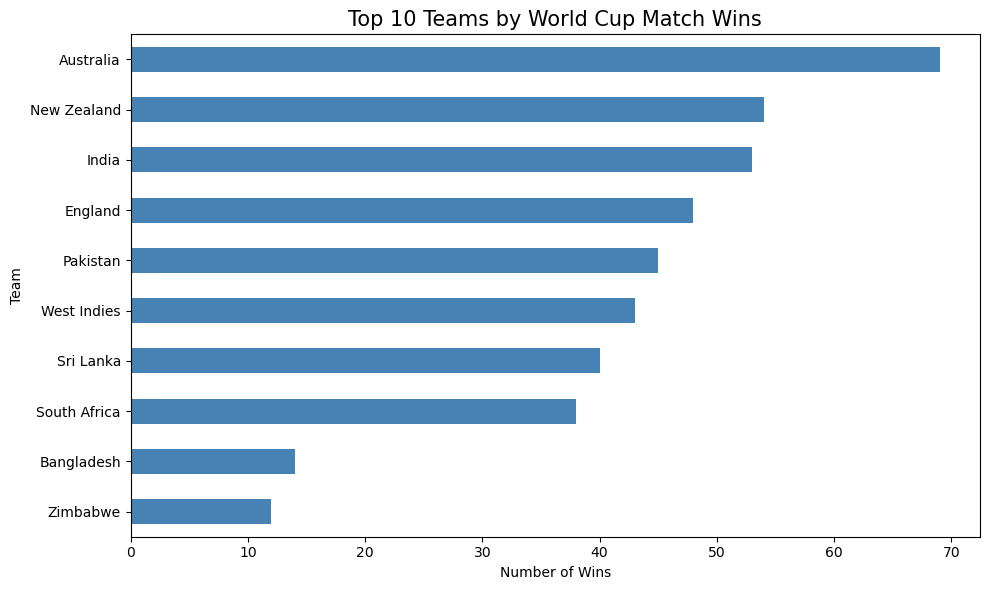

In [53]:
#Graph 1: Which teams have won the most matches?

team_wins = df["winner"].value_counts().head(10)

plt.figure(figsize=(10, 6))

team_wins.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Teams by World Cup Match Wins",
          fontsize=15)
plt.xlabel("Number of Wins")
plt.ylabel("Team")
plt.tight_layout()
plt.show()



### 🔍 Key Insights – Top 10 Teams by World Cup Match Wins

- **Australia** leads the dataset with **69 match wins**, making it the most successful team by total wins in the recorded matches.
- **New Zealand** ranks second with **54 wins**, followed closely by **India** with **53 wins**.
- **England (48 wins)** and **Pakistan (45 wins)** also show strong performances in the dataset.
- **West Indies (43 wins)** and **Sri Lanka (40 wins)** occupy the middle positions among the top eight teams.
- **South Africa (38 wins)**, **Bangladesh (14 wins)**, and **Zimbabwe (12 wins)** complete the top 10 teams shown in the chart.
- The difference between total wins can reflect the number of matches played as well as team performance. Therefore, win percentage would provide a more balanced comparison.

### 💡 Conclusion

Australia has the highest recorded number of World Cup match wins in this dataset, followed by New Zealand and India. For a deeper comparison, analyze each team's win percentage alongside total matches played.


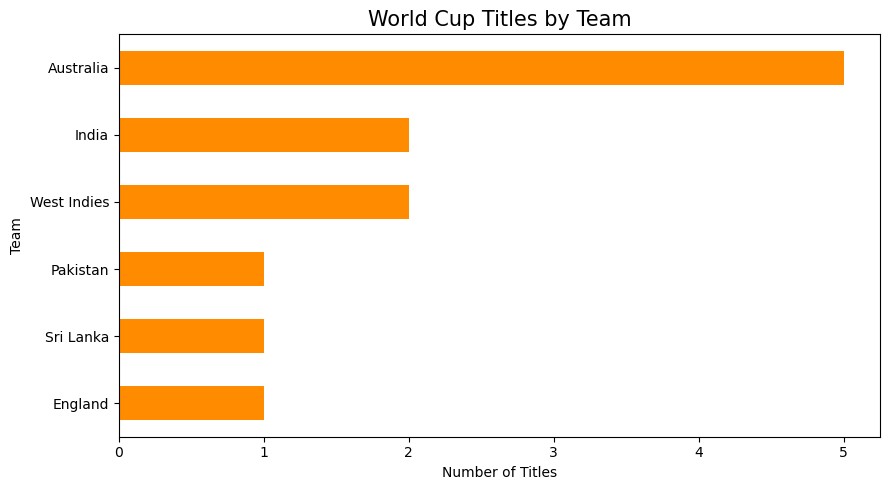

In [54]:
#Graph 2: Which teams have won the most World Cup titles?

champions = df[["season", "season_winner"]].drop_duplicates()

title_counts = champions["season_winner"].value_counts()

plt.figure(figsize=(9, 5))

title_counts.sort_values().plot(
    kind="barh",
    color="darkorange"
)

plt.title("World Cup Titles by Team", fontsize=15)
plt.xlabel("Number of Titles")
plt.ylabel("Team")
plt.tight_layout()
plt.show()


### 🔍 Key Insights – World Cup Titles by Team

- 🥇 **Australia** leads the dataset with **5 recorded World Cup titles**, making it the team with the highest title count in this analysis.
- 🏆 **West Indies** and **India** are tied in second place, with **2 recorded titles each**.
- 📊 **Pakistan, Sri Lanka, and England** have **1 recorded title each** in the dataset.
- 🏏 Australia has the highest number of titles among the teams represented in the chart.
- 📈 The chart highlights differences in recorded championship success across teams.

### 💡 Conclusion

Australia has the highest recorded title count in this dataset, followed by West Indies and India. These results depend on the `season_winner` and `season` columns, so the season labels and champion records should be verified before drawing final conclusions.



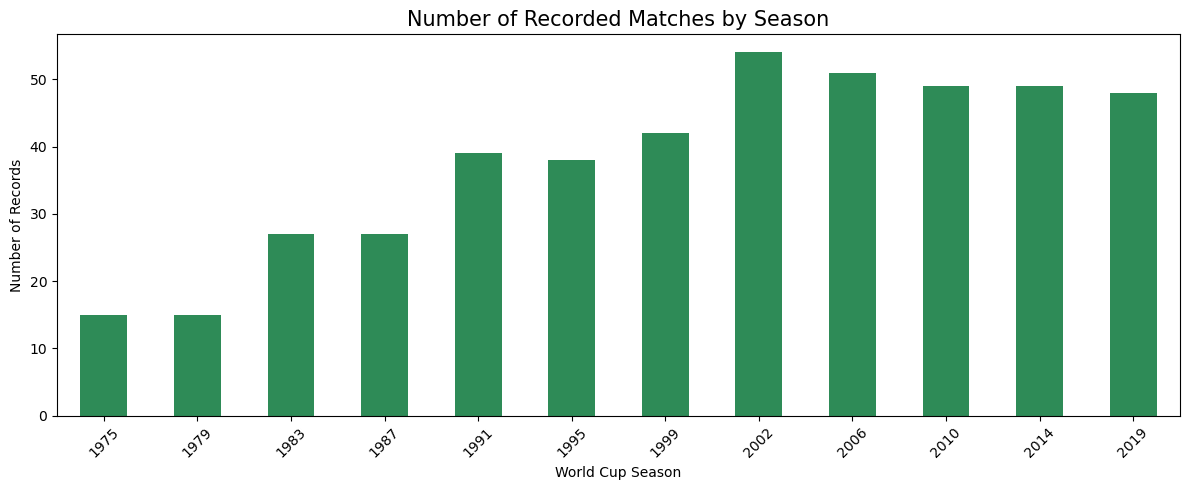

In [30]:
#Graph 3: How many matches were played in each season?

matches_by_season = df["season"].value_counts()

# Sort season labels for chronological display
matches_by_season = matches_by_season.sort_index()

plt.figure(figsize=(12, 5))

matches_by_season.plot(
    kind="bar",
    color="seagreen"
)

plt.title("Number of Recorded Matches by Season",
          fontsize=15)
plt.xlabel("World Cup Season")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### 🔍 Key Insights – Number of Recorded Matches by Season

- 📊 The graph shows the number of match records available for each World Cup season in the dataset.
- 🏏 Differences in bar heights indicate that the dataset contains different numbers of recorded matches across seasons.
- 📈 Comparing seasons helps identify variations in the volume of match records over time.
- 🔎 Seasons with unusually high or low counts should be checked to determine whether the differences reflect the tournament schedule or incomplete data.
- ⚠️ The season labels should be validated before interpreting the chart as a chronological trend.

### 💡 Conclusion

This visualization provides an overview of how recorded World Cup matches are distributed across seasons. Verifying season labels and match counts will help ensure accurate historical comparisons.


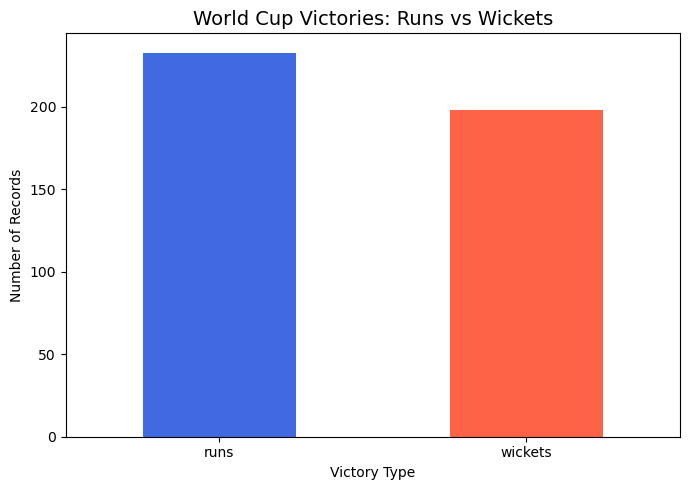

In [56]:
#Graph 4: Matches won by runs vs wickets

result_counts = (
    df["margin_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "run": "runs",
        "wicket": "wickets"
    })
    .value_counts()
)

result_counts = result_counts.reindex(
    ["runs", "wickets"]
).dropna()

plt.figure(figsize=(7, 5))

result_counts.plot(
    kind="bar",
    color=["royalblue", "tomato"]
)

plt.title("World Cup Victories: Runs vs Wickets",
          fontsize=14)
plt.xlabel("Victory Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### 🔍 Key Insights – World Cup Victories: Runs vs Wickets

- 🏏 This graph compares the number of recorded World Cup victories achieved by runs and by wickets.
- 📊 **Wins by runs** represent matches where the winning team scored more runs than its opponent.
- 🎯 **Wins by wickets** represent matches where the winning team successfully chased the target before losing all its wickets.
- 📈 Comparing both categories helps identify which type of victory occurs more frequently in the dataset.
- 🔎 The difference between the two categories may reflect variations in match conditions, batting performance, and successful run chases.

### 💡 Conclusion

This visualization provides a comparison of run-based and wicket-based victories in World Cup matches. The category with the taller bar represents the more frequently recorded victory type in this dataset.


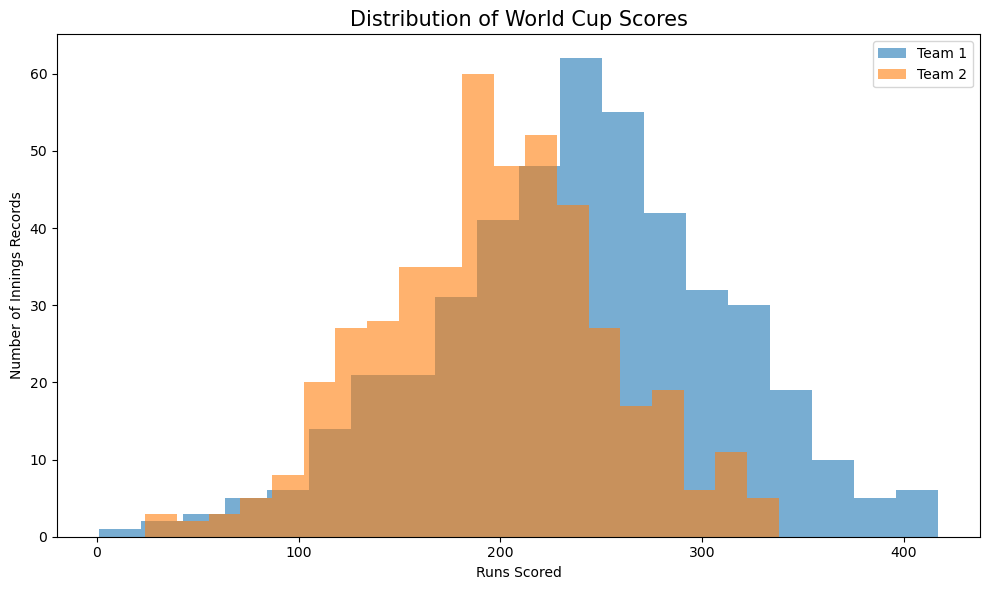

In [57]:
#Graph 5: Distribution of team scores

# Extract runs without changing the original score columns
team_1_runs = pd.to_numeric(
    df["team_1_score"].astype("string")
      .str.extract(r"(\d+)")[0],
    errors="coerce"
)

team_2_runs = pd.to_numeric(
    df["team_2_score"].astype("string")
      .str.extract(r"(\d+)")[0],
    errors="coerce"
)

plt.figure(figsize=(10, 6))

plt.hist(
    team_1_runs.dropna(),
    bins=20,
    alpha=0.6,
    label="Team 1"
)

plt.hist(
    team_2_runs.dropna(),
    bins=20,
    alpha=0.6,
    label="Team 2"
)

plt.title("Distribution of World Cup Scores",
          fontsize=15)
plt.xlabel("Runs Scored")
plt.ylabel("Number of Innings Records")
plt.legend()
plt.tight_layout()
plt.show()



### 🔍 Key Insights – Distribution of World Cup Match Scores

- 📊 The histogram shows how World Cup match scores are distributed across different scoring ranges.
- 🏏 It helps identify the score ranges that occur most frequently in the dataset.
- 📈 The shape of the distribution can reveal whether scores are concentrated around a common range or spread across a wider range.
- 🔎 Scores in the higher ranges represent matches with larger team totals, while lower scores may reflect lower-scoring matches.
- ⚖️ Comparing the distributions of Team 1 and Team 2 can help reveal differences in their recorded scoring patterns.

### 💡 Conclusion

The score-distribution graph provides an overview of scoring patterns in World Cup matches and helps identify common and less common score ranges.


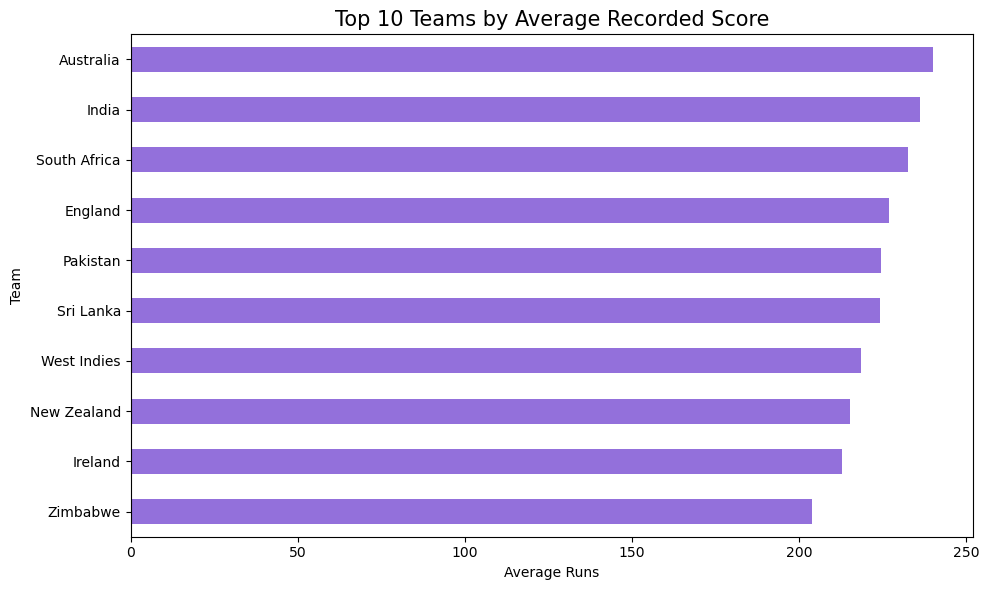

In [58]:
#Graph 6: Which teams score the most runs on average?

team1_data = pd.DataFrame({
    "team": df["team_1"],
    "runs": team_1_runs
})

team2_data = pd.DataFrame({
    "team": df["team_2"],
    "runs": team_2_runs
})

all_team_scores = pd.concat(
    [team1_data, team2_data],
    ignore_index=True
).dropna(subset=["team", "runs"])

average_scores = (
    all_team_scores
    .groupby("team", observed=True)["runs"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

average_scores.sort_values().plot(
    kind="barh",
    color="mediumpurple"
)

plt.title("Top 10 Teams by Average Recorded Score",
          fontsize=15)
plt.xlabel("Average Runs")
plt.ylabel("Team")
plt.tight_layout()
plt.show()



### 🔍 Key Insights – Top 10 Teams by Average Recorded Score

- 🏏 This graph ranks the top 10 teams based on their average recorded runs in the dataset.
- 📊 Teams appearing higher on the chart have a greater average score across the recorded innings included in the analysis.
- 📈 The comparison highlights differences in scoring performance among the top 10 teams.
- 🔎 A higher average score does not necessarily mean a team wins more matches, as match outcomes also depend on the opponent's score and other match conditions.
- ⚖️ The number of valid innings should also be considered, because averages based on fewer records may be less representative.

### 💡 Conclusion

The visualization identifies the teams with the highest average recorded scores in the dataset. It provides a useful view of scoring performance, complementing the total-win analysis in Graph 1.

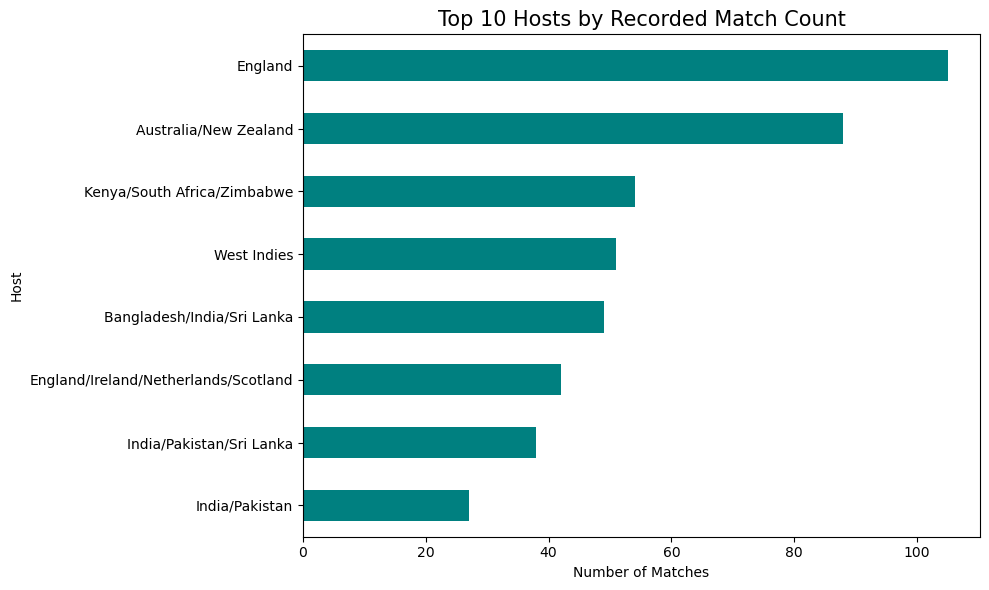

In [59]:
#Graph 7: Which host locations recorded the most matches?

host_counts = df["host"].value_counts().head(10)

plt.figure(figsize=(10, 6))

host_counts.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 10 Hosts by Recorded Match Count",
          fontsize=15)
plt.xlabel("Number of Matches")
plt.ylabel("Host")
plt.tight_layout()
plt.show()



### 🔍 Key Insights – Top 10 Hosts by Recorded Match Count

- 🏏 This graph highlights the top 10 host countries based on the number of World Cup matches recorded in the dataset.
- 📊 Countries with taller bars have more recorded matches associated with them than countries with shorter bars.
- 🌍 The ranking helps identify which host countries account for the largest number of matches in the dataset.
- 📈 Differences in match counts may reflect the number of tournaments hosted and the number of matches played during those tournaments.
- 🔎 This visualization provides a clear comparison of hosting activity across the top 10 countries.

### 💡 Conclusion

The graph ranks the top 10 host countries by recorded match count, making it easier to compare hosting activity and identify countries with the highest match totals in the dataset.

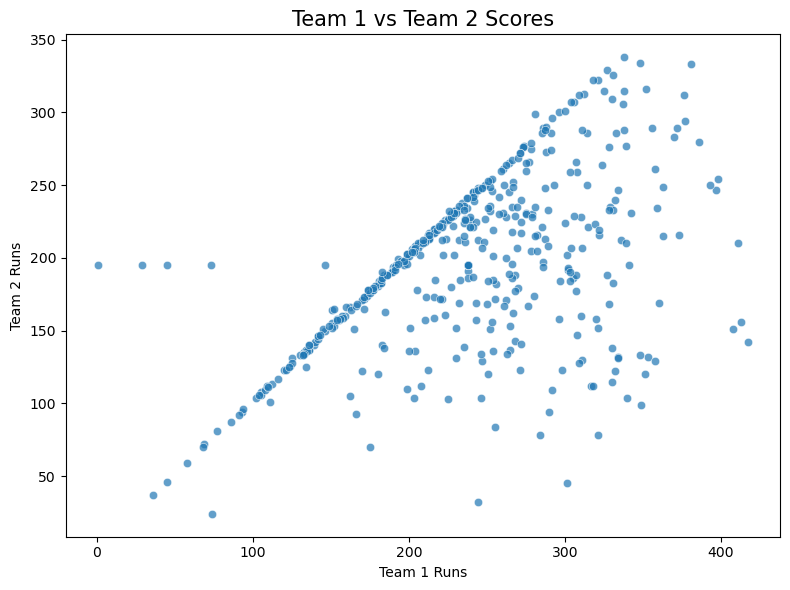

In [60]:
#Graph 8: Explore the relationship between team scores

score_comparison = pd.DataFrame({
    "Team 1 Runs": team_1_runs,
    "Team 2 Runs": team_2_runs
}).dropna()

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=score_comparison,
    x="Team 1 Runs",
    y="Team 2 Runs",
    alpha=0.7
)

plt.title("Team 1 vs Team 2 Scores", fontsize=15)
plt.xlabel("Team 1 Runs")
plt.ylabel("Team 2 Runs")
plt.tight_layout()
plt.show()



### 🔍 Key Insights – Relationship Between Team Scores

- 🏏 This scatter plot compares the scores of Team 1 and Team 2 across recorded World Cup matches.
- 📊 Each point represents a match, showing the relationship between the two teams' scores.
- 📈 Points where both teams score highly indicate matches in which both sides achieved relatively high totals.
- ⚖️ Points far from the main cluster may represent matches with unusually high or low scores.
- 🔎 The distribution of points helps explore whether higher scores by one team are associated with higher scores by the opposing team.
- 🎯 The plot provides a visual comparison of scoring patterns, but it does not by itself establish a cause-and-effect relationship.

### 💡 Conclusion

This visualization helps explore scoring patterns between opposing teams and identify similarities, differences, and unusual score combinations across recorded World Cup matches.

In [62]:
#Key Performance Indicators (KPI) summary

# Total match records
total_matches = len(df)

# Number of unique teams
all_teams = pd.concat([
    df["team_1"],
    df["team_2"]
]).dropna().nunique()

# Number of tournament seasons
total_seasons = df["season"].nunique()

# Most frequent winner label
most_frequent_winner = df["winner"].value_counts().index[0]

# Average scores
team1_avg = team_1_runs.mean()
team2_avg = team_2_runs.mean()

print("WORLD CUP DATA ANALYSIS - KPI SUMMARY")
print("-" * 40)
print("Total match records:", total_matches)
print("Unique teams:", all_teams)
print("Tournament seasons:", total_seasons)
print("Most frequent winner label:", most_frequent_winner)
print("Average Team 1 score:", round(team1_avg, 2))
print("Average Team 2 score:", round(team2_avg, 2))


WORLD CUP DATA ANALYSIS - KPI SUMMARY
----------------------------------------
Total match records: 454
Unique teams: 20
Tournament seasons: 12
Most frequent winner label: Australia
Average Team 1 score: 238.22
Average Team 2 score: 195.96


In [63]:
#Analyse match outcomes

print(df["winner"].value_counts(dropna=False))


winner
Australia                                69
New Zealand                              54
India                                    53
England                                  48
Pakistan                                 45
West Indies                              43
Sri Lanka                                40
South Africa                             38
Bangladesh                               14
Zimbabwe                                 12
No result                                 8
Ireland                                   7
Kenya                                     7
Match abandoned without a ball bowled     5
Match tied                                4
Canada                                    2
Netherlands                               2
Match tied (D/L method)                   1
U.A.E.                                    1
Afghanistan                               1
Name: count, dtype: int64


In [64]:
#Analyse winning margins

df["margin_numeric"] = pd.to_numeric(
    df["margin"].astype("string")
      .str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

print(df[["winner", "margin", "margin_type",
          "margin_numeric"]].head(10))

print("\nWinning margin statistics:")
print(df["margin_numeric"].describe())


        winner margin margin_type  margin_numeric
0      England  104.0        runs           104.0
1  West Indies    7.0     wickets             7.0
2  New Zealand   10.0     wickets            10.0
3    Australia    7.0     wickets             7.0
4   Bangladesh   21.0        runs            21.0
5     Pakistan   14.0        runs            14.0
6    Sri Lanka   34.0        runs            34.0
7        India    6.0     wickets             6.0
8  New Zealand    2.0     wickets             2.0
9    Australia   15.0        runs            15.0

Winning margin statistics:
count        431.0
mean     46.566125
std      58.538158
min            1.0
25%            7.0
50%           10.0
75%           74.5
max          275.0
Name: margin_numeric, dtype: Float64


In [65]:
#Create a season-wise champion report

season_report = (
    df[["season", "season_winner"]]
    .drop_duplicates()
    .sort_values("season")
    .reset_index(drop=True)
)

season_report.columns = [
    "World Cup Season",
    "Champion"
]

print(season_report.to_string(index=False))


 World Cup Season    Champion
             1975 West Indies
             1979 West Indies
             1983       India
             1987   Australia
             1991    Pakistan
             1995   Sri Lanka
             1999   Australia
             2002   Australia
             2006   Australia
             2010       India
             2014   Australia
             2019     England


In [66]:
#Find the top-scoring matches

match_scores = df.copy()

match_scores["combined_runs"] = (
    team_1_runs + team_2_runs
)

top_scoring_matches = match_scores.nlargest(
    10, "combined_runs"
)

print(
    top_scoring_matches[[
        "date", "team_1", "team_2",
        "team_1_score", "team_2_score",
        "combined_runs", "winner"
    ]].to_string(index=False)
)


               date      team_1       team_2  team_1_score  team_2_score  combined_runs      winner
2019-06-20 00:00:00   Australia   Bangladesh         381.0         333.0            714   Australia
2015-03-08 00:00:00   Australia    Sri Lanka         376.0         312.0            688   Australia
2019-06-03 00:00:00    Pakistan      England         348.0         334.0            682    Pakistan
2011-02-27 00:00:00       India      England         338.0         338.0            676  Match tied
2007-03-24 00:00:00   Australia South Africa         377.0         294.0            671   Australia
2019-06-09 00:00:00       India    Australia         352.0         316.0            668       India
2019-06-08 00:00:00     England   Bangladesh         386.0         280.0            666     England
2015-02-24 00:00:00 West Indies     Zimbabwe         372.0         289.0            661 West Indies
2015-03-07 00:00:00     Ireland     Zimbabwe         331.0         326.0            657     Ireland


# Cricket World Cup Data Analysis — Key Findings

## 1. Dataset overview
The dataset contains historical Cricket World Cup match records across multiple tournament seasons.

## 2. Team performance
The team-wins analysis identifies which teams have the highest recorded number of match victories.

## 3. Tournament champions
The season-wise champion analysis compares the number of World Cup titles won by each team.

## 4. Scoring patterns
The score distribution and average-score analysis reveal common scoring ranges and unusually high scores.

## 5. Match outcomes
The outcome analysis distinguishes team victories from tied and no-result matches.

## 6. Winning margins
The winning-margin analysis compares numerical margins separately for victories by runs and wickets.

## 7. Limitations
Some scores and result details are missing. The dataset also contains date ranges and categorical labels that require careful interpretation.

## Conclusion
This project uses Python, Pandas, NumPy, Matplotlib, and Seaborn to explore historical Cricket World Cup data, identify patterns, and communicate findings through visualizations.

In [69]:
#Export your analysis results

# Save the updated dataset
df.to_csv("worldcup_analysis_dataset.csv", index=False)

# Save the champion report
season_report.to_csv("worldcup_champions.csv", index=False)

print("Analysis files saved successfully!")


Analysis files saved successfully!
